In [2]:
# !pip install -q -U langchain-nebius langchain langgraph rich python-dotenv tavily-python

In [3]:
from dotenv import load_dotenv
from langchain_community.tools import TavilySearchResults
import os
from langgraph.prebuilt import ToolNode
from rich.console import Console  # Console styling
from rich.markdown import Markdown  # Render markdown in terminal
from rich.syntax import Syntax

from common import LLM_MODEL, API_BASE, API_KEY

load_dotenv(override=True)



console = Console()
console.print(LLM_MODEL,API_BASE)


deepseek-v4-flash https://api.deepseek.com/anthropic

In [4]:

# Initialize the tool. We can set the max number of results to keep the context concise.
search_tool = TavilySearchResults(max_results=2)
# It's crucial to give the tool a clear name and description for the agent
search_tool.name = "web_search"
search_tool.description = "A tool that can be used to search the internet for up-to-date information on any topic, including news, events, and current affairs."
tools = [search_tool]

# Let's test the tool directly to see its output format
print("\n--- Testing the tool directly ---")
test_query = "What was the score of the last Super Bowl?"
test_result = search_tool.invoke({"query": test_query})
console.print(f"[bold green]Query:[/bold green] {test_query}")
console.print("\n[bold green]Result:[/bold green]")
console.print(test_result)

/var/folders/7j/f64kzz4975l059ybdt7bp9qm0000gn/T/ipykernel_11767/3158819452.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  search_tool = TavilySearchResults(max_results=2)



--- Testing the tool directly ---


Query: What was the score of the last Super Bowl?

Result:

[
    {
        'title': 'List of Super Bowl champions',
        'url': 'https://en.wikipedia.org/wiki/List_of_Super_Bowl_champions',
        'content': 'Super Bowl championships\n| Game | Date (season) | Winning team | Score | Losing team | Score |
Venue | City | Attendance | Referee | Ref. |\n ---  ---  ---  ---  --- \n| I ( | Jan 15, 1967 (1966 AFL/1966 NFL) |
Green Bay Packersn (1, 1–0) | 35 | Kansas City Chiefsa (1, 0–1) | 10 | Los Angeles Memorial Coliseum | Los Angeles,
California( | 61,946 | Norm Schachter | ( |\n| II ( | Jan 14, 1968 (1967 AFL/1967 NFL) | Green Bay Packersn (2, 
2–0) | 33 | Oakland Raidersa (1, 0–1) | 14 | Miami Orange Bowl | Miami, Florida( | 75,546 | Jack Vest | ( |\n| III 
( | Jan 12, 1969 (1968 AFL/1968 NFL) | New York Jetsa (1, 1–0) | 16 | Baltimore Coltsn (1, 0–1) | 7 | Miami Orange 
Bowl (2) | Miami, Florida (2)( | 75,389 | Tom Bell "Tommy Bell (American football official)") | ( |\n| IV ( | Jan 
11, 1970 (1969 AFL/1969 NFL) | Kansas City Chiefsa (2, 1–1) | 23 | Minnesota Vikingsn (1, 0–1) | 7 | Tulane Stadium
| New Orleans, Louisiana | 80,562 | John McDonough "John McDonough (American football referee)") | ( |\n| V | Jan 
17, 1971 (1970) | Baltimore ColtsA (2, 1–1) | 16 | Dallas CowboysN (1, 0–1) | 13 | Miami Orange Bowl (3) | Miami, 
Florida (3)( | 79,204 | Norm Schachter | ( |\n| VI | Jan 16, 1972 (1971) | Dallas CowboysN (2, 1–1) | 24 | Miami 
DolphinsA (1, 0–1) | 3 | Tulane Stadium (2) | New Orleans, Louisiana (2) | 81,023 | Jim Tunney "Jim Tunney 
(American football)") | ( || VII | Jan 14, 1973 (1972) | Miami DolphinsA (2, 1–1) | 14 | Washington RedskinsN (1, 
0–1) | 7 | Los Angeles Memorial Coliseum (2) | Los Angeles, California (2)( | 90,182 | Tom Bell "Tommy Bell 
(American football official)") | ( |\n| VIII | Jan 13, 1974 (1973) | Miami DolphinsA (3, 2–1) | 24 | Minnesota 
VikingsN (2, 0–2) | 7 | Rice Stadium "Rice Stadium (Rice University)")( | Houston, Texas | 71,882 | Ben Dreith | ( 
|\n| IX | Jan 12, 1975 (1974) | Pittsburgh SteelersA (1, 1–0) | 16 | Minnesota VikingsN (3, 0–3) | 6 | Tulane 
Stadium (3) | New Orleans, Louisiana (3) | 80,997 | Bernie Ulman | ( |\n| X | Jan 18, 1976 (1975) | Pittsburgh 
SteelersA (2, 2–0) | 21 | Dallas CowboysN (3, 1–2)( | 17 | Miami Orange Bowl (4) | Miami, Florida (4)( | 80,187 | 
Norm Schachter | ( |\n| XI | Jan 9, 1977 (1976) | Oakland RaidersA (2, 1–1) | 32 | Minnesota VikingsN (4, 0–4) | 14
| Rose Bowl "Rose Bowl (stadium)")( | Pasadena, California (3)( | 103,438 | Jim Tunney "Jim Tunney (American 
football)") | ( |\n| XII | Jan 15, 1978 (1977) | Dallas CowboysN (4, 2–2) | 27 | Denver BroncosA (1, 0–1) | 10 | 
Louisiana Superdome( | New Orleans, Louisiana (4) | 76,400 | Jim Tunney "Jim Tunney (American football)") | ( |\n| 
XIII | Jan 21, 1979 (1978) | Pittsburgh SteelersA (3, 3–0) | 35 | Dallas CowboysN (5, 2–3) | 31 | Miami Orange Bowl
(5) | Miami, Florida (5)( | 79,484 | Pat Haggerty "Pat Haggerty (American football official)") | ( || XIV | Jan 20,
1980 (1979) | Pittsburgh SteelersA (4, 4–0) | 31 | Los Angeles RamsN (1, 0–1) | 19 | Rose Bowl "Rose Bowl 
(stadium)") (2)( 7]]( | Pasadena, California (4)( | 103,985 | Fred Silva | ( |\n| XV | Jan 25, 1981 (1980) | 
Oakland RaidersA (3, 2–1)( | 27 | Philadelphia EaglesN (1, 0–1) | 10 | Louisiana Superdome (2)( | New Orleans, 
Louisiana (5) | 76,135 | Ben Dreith | ( |\n| XVI | Jan 24, 1982 (1981) | San Francisco 49ersN (1, 1–0) | 26 | 
Cincinnati BengalsA (1, 0–1) | 21 | Pontiac Silverdome | Pontiac, Michigan( | 81,270 | Pat Haggerty "Pat Haggerty 
(American football official)") | ( |\n| XVII | Jan 30, 1983 (1982) | Washington RedskinsN (2, 1–1) | 27 | Miami 
DolphinsA (4, 2–2) | 17 | Rose Bowl "Rose Bowl (stadium)") (3)( | Pasadena, California (5)( | 103,667 | Jerry 
Markbreit | ( |\n| XVIII | Jan 22, 1984 (1983) | Los Angeles RaidersA (4, 3–1) | 38 | Washington RedskinsN (3, 1–2)
| 9 | Tampa Stadium | Tampa, Florida | 72,980 | Gene Barth | ( |\n| XIX | Jan 20, 1985 (1984) | San Francisco 
49ersN

In [5]:
from typing import Annotated


from langchain_anthropic import ChatAnthropic
from langchain_core.messages import AnyMessage
from typing_extensions import TypedDict
from langgraph.graph import add_messages


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

llm = ChatAnthropic(
    model_name=LLM_MODEL,
    api_key=API_KEY,
    base_url=API_BASE,
    max_tokens=16000,
)

llm_with_tools = llm.bind_tools(tools=tools)

In [6]:

def agent_node(state: AgentState):
    """The primary node that calls the LLM to decide the next action."""
    console.print("--- AGENT: Thinking... ---")
    response = llm_with_tools.invoke(state["messages"])
    console.print(f"--- AGENT: Response-----")
    return {"messages": [response]}

# The ToolNode is a pre-built node from LangGraph that executes tools
tool_node = ToolNode(tools)

In [7]:
def router_function(state: AgentState) -> str:
    """Inspects the agent's last message to decide the next step."""
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        # The agent has requested a tool call
        console.print(f"--- ROUTER: Decision is to call a tool. ---")
        return "call_tool"
    else:
        # The agent has provided a final answer
        console.print(f"--- ROUTER: Decision is to finish.---")
        return "__end__"

In [8]:
from langgraph.graph import StateGraph


graph_builder = StateGraph(AgentState)

# Add the nodes
graph_builder.add_node("agent", agent_node)
graph_builder.add_node("call_tool", tool_node)

# Set the entry point
graph_builder.set_entry_point("agent")

# Add the conditional router
graph_builder.add_conditional_edges(
    "agent",
    router_function,
)

# Add the edge from the tool node back to the agent to complete the loop
# graph_builder.add_edge( "agent","call_tool")
graph_builder.add_edge("call_tool", "agent")

# Compile the graph
tool_agent_app = graph_builder.compile()

Tool-using agent graph compiled successfully!


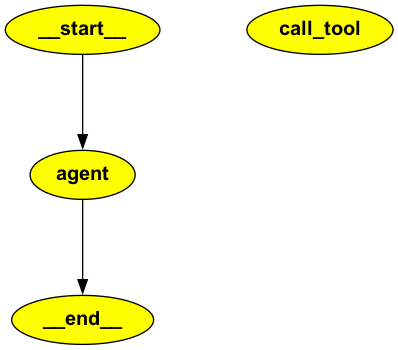

In [9]:
print("Tool-using agent graph compiled successfully!")

# Visualize the graph
try:
    from IPython.display import Image, display
    png_image = tool_agent_app.get_graph().draw_png()
    display(Image(png_image))
except Exception as e:
    print(f"Graph visualization failed: {e}. Please ensure pygraphviz is installed.")

In [10]:
from rich.console import Console  # Console styling
from rich.markdown import Markdown  # Render markdown in terminal
from rich.syntax import Syntax



user_query = "What were the main announcements from Apple's latest WWDC event?"
initial_input = {"messages": [("user", user_query)]}

console.print(f"[bold cyan]🚀 Kicking off Tool Use workflow for request:[/bold cyan] '{user_query}'\n")

for chunk in tool_agent_app.stream(initial_input, stream_mode="values"):
    chunk["messages"][-1].pretty_print()
    console.print("\n---\n")


console.print("\n[bold green]✅ Tool Use workflow complete![/bold green]")

🚀 Kicking off Tool Use workflow for request: 'What were the main announcements from Apple's latest WWDC event?'

================================ Human Message =================================

What were the main announcements from Apple's latest WWDC event?


---

--- AGENT: Thinking... ---

--- AGENT: Response-----

...

--- AGENT: Response-----

--- ROUTER: Decision is to finish.---

================================== Ai Message ==================================

[{'signature': '5da7d81f-0b17-4f0d-9600-05caafa0023d', 'thinking': 'Now I have good info about WWDC 2026 (held June 8, 2026). Let me compile the main announcements. I have enough. Let me maybe do one more search to confirm details like hardware teases, other OS versions.\n\nActually I have enough to give a solid answer. Let me summarize WWDC 2026\'s main announcements.\n\nKey points:\n1. Siri AI overhaul - rebuilt Siri powered by Apple Foundation Models based on Google Gemini (multi-year Apple-Google partnership announced Jan 2026). Personal context, conversational, onscreen awareness, app actions. Standalone Siri app for iPhone, iPad, Mac.\n2. iOS 27, iPadOS 27, macOS 27 ("Golden Gate"), watchOS 27, visionOS 27, tvOS 27.\n3. Liquid Glass design refinements - "Glass Intensity Slider" for readability.\n4. Apple Intelligence across system, Foundation Models framework for devs.\n5. Search infrastructure over

---

✅ Tool Use workflow complete!

In [11]:
from pydantic import BaseModel, Field


class ToolUseEvaluation(BaseModel):
    """Schema for evaluating the agent's tool use and final answer."""
    tool_selection_score: int = Field(description="Score 1-5 on whether the agent chose the correct tool for the task.")
    tool_input_score: int = Field(description="Score 1-5 on how well-formed and relevant the input to the tool was.")
    synthesis_quality_score: int = Field(description="Score 1-5 on how well the agent integrated the tool's output into its final answer.")
    justification: str = Field(description="A brief justification for the scores.")

In [12]:
judge_llm = llm.with_structured_output(ToolUseEvaluation)

# To evaluate, we need to reconstruct the full conversation trace
final_answer = tool_agent_app.invoke(initial_input)
conversation_trace = "\n".join([f"{m.type}: {m.content or ''} {getattr(m, 'tool_calls', '')}" for m in final_answer['messages']])

def evaluate_tool_use(trace: str):
    prompt = f"""You are an expert judge of AI agents. Evaluate the following conversation trace based on the agent's tool use on a scale of 1-5. Provide a brief justification.
    
    Conversation Trace:
    ```
    {trace}
    ```
    """
    return judge_llm.invoke(prompt)

console.print("--- Evaluating Tool Use Performance ---")
evaluation = evaluate_tool_use(conversation_trace)
console.print(evaluation.model_dump())

--- AGENT: Thinking... ---

--- AGENT: Response-----

--- ROUTER: Decision is to call a tool. ---

--- AGENT: Thinking... ---

--- AGENT: Response-----

...

--- AGENT: Thinking... ---

--- AGENT: Response-----

--- ROUTER: Decision is to finish.---

--- Evaluating Tool Use Performance ---

BadRequestError: Error code: 400 - {'error': {'message': 'Thinking mode does not support this tool_choice (request_id: 2d9b0d26-e93e-4353-b5a3-9ba30c3e1edd)', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_request_error'}}